# EDA — Denuncias policiales SIDPOL para el Eje 2 (ruta peatonal segura)

| | |
|---|---|
| **Dataset** | Denuncias policiales registradas (SIDPOL, MININTER), Lima y Callao, unificadas desde 140 CSV y 3 GeoJSON |
| **Grano** | una fila = una denuncia (`id_dgc` único) |
| **Periodo** | fecha del hecho; se explora **train (≤2022) + valid (2023)**. El **test (enero–agosto de 2024) está sellado** y la reserva (sep 2024–jun 2025, baja cobertura) no se usa: aquí solo se lee `manifest.json` |
| **Para qué** | decidir qué filas sirven para estimar riesgo por calle alrededor de estaciones y paraderos, y qué hay que corregir |
| **Salida** | `data_processed/eje2/clean/denuncias_eje2_clean.parquet` + documento `docs/EDA_Eje2.md` |


In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve().parents[2]            # deliveries/week12
sys.path.insert(0, str(RAIZ / "code" / "eje2"))
import eje2_common as C

BASE  = RAIZ / "data_processed" / "eje2"
SPL   = BASE / "splits"
CLEAN = BASE / "clean"
FIGS  = RAIZ / "docs" / "images"
for p in (CLEAN, FIGS): p.mkdir(parents=True, exist_ok=True)
SEED = 0
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
AZUL, GRIS, ROJO = "#1f4fd8", "#8a94a6", "#d64545"

def guardar_fig(nombre):
    plt.savefig(FIGS / nombre, bbox_inches="tight"); plt.show()

def cramer_v(a, b):
    t = pd.crosstab(a, b); chi2, p, _, _ = chi2_contingency(t)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p

## 1. Carga e inspección — ¿qué vamos a hacer?

Leer **solo** `train.parquet` y `valid.parquet` (el test queda sellado), ver dimensiones, tipos y memoria, y comprobar que
la partición temporal del `manifest.json` coincide con lo que cargamos. Cualquier decisión de limpieza se toma con estos
datos y se aplica después, sin cambios, al test.

In [2]:
man = json.loads((SPL / "manifest.json").read_text())
print({k: (v["filas"], v["desde"][:10], v["hasta"][:10]) for k, v in man["splits"].items()})
tr = pd.read_parquet(SPL / "train.parquet"); va = pd.read_parquet(SPL / "valid.parquet")
tr["split"], va["split"] = "train", "valid"
d = pd.concat([tr, va], ignore_index=True); del tr, va
print(f"train+valid: {len(d):,} filas x {d.shape[1]} columnas · {d.memory_usage(deep=True).sum()/1e9:.1f} GB en memoria")
print("id_dgc único:", d.id_dgc.is_unique)
print(d.dtypes.value_counts().to_string())

{'train': (1603871, '1923-05-31', '2022-12-31'), 'valid': (446179, '2023-01-01', '2023-12-31'), 'test': (283138, '2024-01-01', '2024-08-31'), 'reserva': (261144, '2024-09-01', '2025-06-30')}


train+valid: 2,050,050 filas x 59 columnas · 5.6 GB en memoria
id_dgc único: True
string[python]    43
Int64              9
datetime64[ns]     3
float64            3
object             1


### Qué encontramos (carga)

- Se cargaron **2 050 050 denuncias** (train 1 603 871 + valid 446 179) con 59 columnas: 57 originales, `origen` y `split`. Ocupan 5,6 GB en memoria, por eso el dato vive en parquet y no en CSV.
- `id_dgc` es único: la unificación de los 143 archivos no dejó duplicados.
- El **test** (283 138 filas, enero–agosto de 2024) y la **reserva** (261 144 filas, septiembre de 2024 a junio de 2025) **no se abrieron**: solo se leyeron sus conteos del manifest.
- 43 columnas son texto, 9 son enteros, 3 son fechas y 3 son decimales (`lat_hecho`, `long_hecho`, `indice_priorizacion`).

**Decisión:** seguir con train + valid. Todo lo que se decida abajo se aplica luego, tal cual, al test.

## 2. Calidad y análisis de nulos — ¿qué vamos a hacer?

1. Medir nulos por columna y decidir qué columnas se descartan.
2. Buscar **nulos disfrazados**: valores que no están vacíos pero equivalen a "no sabemos" (por ejemplo una coordenada
   puesta en el centroide de la comisaría).
3. Preguntar si la falta de coordenada real es **MCAR** (totalmente aleatoria), **MAR** (depende de variables que sí vemos:
   comisaría, año, tipo de hecho…) o **MNAR** (depende del propio valor faltante, es decir, de *dónde* ocurrió el hecho).
   Para eso: V de Cramér con chi-cuadrado y una regresión logística de "falta coordenada real" con conjuntos crecientes de variables.

In [3]:
nulos = d.isna().mean().mul(100).round(1)
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(nulos.to_string())
COL_SOLO_CAPA = ["tipologias_ia", "cuadra_hecho", "departamento", "provincia", "distrito", "barrio", "comisaria",
                 "fecha_inaguracion", "indice_priorizacion"]
print("\nColumnas con >95 % de nulos:", [c for c in nulos.index if nulos[c] > 95])
print("lat/long nulos:", int(d.lat_hecho.isna().sum()), int(d.long_hecho.isna().sum()))

tipologias_ia          100.0
cuadra_hecho            98.0
barrio                  95.9
comisaria               95.9
departamento            95.9
provincia               95.9
distrito                95.9
indice_priorizacion     95.9
fecha_inaguracion       95.9

Columnas con >95 % de nulos: ['tipologias_ia', 'cuadra_hecho', 'barrio', 'comisaria', 'departamento', 'provincia', 'distrito', 'indice_priorizacion', 'fecha_inaguracion']
lat/long nulos: 0 0


### Qué encontramos (nulos por columna)

- Solo **9 de 57 columnas** tienen nulos y todas están casi vacías: `tipologias_ia` (100 %), `cuadra_hecho` (98,0 %) y siete columnas (`barrio`, `comisaria`, `departamento`, `provincia`, `distrito`, `fecha_inaguracion`, `indice_priorizacion`) con 95,9 %. Estas siete vienen de una capa de comisarías pegada al archivo y no describen la denuncia.
- Todas las demás columnas tienen **0 % de nulos**, incluidas `lat_hecho` y `long_hecho`. Eso no significa que haya coordenada de verdad: el nulo está disfrazado (ver abajo).

**Decisión:** descartar las 9 columnas. No se imputa nada en ellas.

In [4]:
apiladas = C.puntos_apilados(d[d.split == "train"])      # puntos 'reales' repetidos >= 500 veces, definidos solo con train
d = C.marcar_calidad(d, apiladas)
pd.DataFrame(sorted(apiladas), columns=["lat", "long"]).to_parquet(CLEAN / "puntos_apilados.parquet", index=False)

print("estado_coord × observacion")
print(pd.crosstab(d.estado_coord, d.observacion).to_string())
print(f"\nCoordenada real (observacion != forzada): {d.coord_real.mean():.1%}   · forzada al centroide: {(~d.coord_real).mean():.1%}")
print("Por año (% con coordenada real):")
print(d.groupby("anio").coord_real.mean().loc[2017:].mul(100).round(1).to_string())

estado_coord × observacion


observacion        COORDENADA ADECUADA MANUALMENTE  COORDENADA ADECUADA MANUALMENTE_A CORREGIR UBIGEO  COORDENADA OK  COORDENADA OK_VERIFICAR UBIGEO  GEO FORZADA AL CENTROIDE DE COMISARIA  VERIFICAR UBIGEO
estado_coord                                                                                                                                                                                                 
CON COORDENADA                                   0                                                  0        1466725                             226                                      0                 7
SIN COORDENADA                                1667                                                368              0                               0                                 581045                 0
SIN COORDENADA XX                                0                                                  0              0                               0                            

### Qué encontramos (nulos disfrazados)

- El campo `estado_coord` **engaña**: marca "SIN COORDENADA" en 2 035 filas que en `observacion` dicen "COORDENADA ADECUADA MANUALMENTE", es decir, alguien las corrigió a mano y sí sirven. El nulo real es `observacion == GEO FORZADA AL CENTROIDE DE COMISARIA`.
- Con esa definición, **28,3 % de las denuncias (581 057) tienen la coordenada puesta en el centroide de una comisaría**, y **71,7 % tienen coordenada real**.
- La cobertura **cae con el tiempo**: 94,0 % en 2018, 70,2 % en 2019, entre 64 % y 70 % en 2020–2023.

**Decisión:** definir `coord_real = observacion != forzada` (columna en `eje2_common.marcar_calidad`) y usar solo esas filas para ubicar eventos en calles.

In [5]:
d["falta"] = ~d.coord_real
filas = []
for v in ["anio", "comisaria_hecho", "distrito_hecho", "turno_hecho", "grupo", "tipo_via_hecho"]:
    s = d[[v, "falta"]].dropna()
    V, p = cramer_v(s[v], s["falta"]); filas.append((v, s[v].nunique(), round(V, 3), f"{p:.1e}"))
print(pd.DataFrame(filas, columns=["variable", "niveles", "V de Cramér", "p (chi²)"]).to_string(index=False))

       variable  niveles  V de Cramér p (chi²)
           anio       46        0.207  0.0e+00
comisaria_hecho      137        0.695  0.0e+00
 distrito_hecho       54        0.412  0.0e+00
    turno_hecho        4        0.179  0.0e+00
          grupo       11        0.696  0.0e+00
 tipo_via_hecho       17        0.471  0.0e+00


**Lectura (asociación con la falta de coordenada):** depende sobre todo de la **comisaría** (V de Cramér 0,70) y del **grupo de hecho** (0,70); el año pesa 0,21 y el turno 0,18. Con millones de filas todas salen con p < 1e-300, por eso se mira el tamaño del efecto (V) y no el valor p.

**Siguiente paso:** un modelo logístico para medir cuánto de esa falta se explica con variables observables.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack, csr_matrix

m = d.sample(300_000, random_state=SEED).copy()
adr = m.direccion_hecho.fillna("").str.upper()
m["adr_len"] = adr.str.len().clip(upper=120) / 120
m["adr_digitos"] = adr.str.count(r"\d").clip(upper=8) / 8
m["adr_mz_lt"] = adr.str.contains(r"\bMZ\b|\bLT\b|\bLOTE\b", regex=True).astype(float)
m["adr_cruce"] = adr.str.contains(r"\bCON\b|\bESQ|\bCRUCE", regex=True).astype(float)
conjuntos = {
    "A. solo año": ["anio"],
    "B. + comisaría": ["anio", "comisaria_hecho"],
    "C. + tipo de hecho y turno": ["anio", "comisaria_hecho", "grupo", "turno_hecho"],
}
y = m.falta.astype(int).values
idx_tr, idx_te = train_test_split(np.arange(len(m)), test_size=0.3, random_state=SEED, stratify=y)
def auc(cols, extra=None):
    X = OneHotEncoder(handle_unknown="ignore").fit_transform(m[cols].astype(str))
    if extra: X = hstack([X, csr_matrix(m[extra].astype(float).values)]).tocsr()
    clf = LogisticRegression(max_iter=300).fit(X[idx_tr], y[idx_tr])
    return roc_auc_score(y[idx_te], clf.predict_proba(X[idx_te])[:, 1])
res = {k: auc(c) for k, c in conjuntos.items()}
res["D. + texto de la dirección"] = auc(conjuntos["C. + tipo de hecho y turno"], ["adr_len", "adr_digitos", "adr_mz_lt", "adr_cruce"])
print(pd.Series(res).round(3).rename("AUC (holdout 30 %)").to_string())
print("\n% sin coordenada real según la dirección tenga o no número:")
print(m.groupby(m.adr_digitos > 0).falta.mean().mul(100).round(1).rename(index={False: "sin dígitos", True: "con dígitos"}).to_string())

A. solo año                   0.602
B. + comisaría                0.928
C. + tipo de hecho y turno    0.971
D. + texto de la dirección    0.973

% sin coordenada real según la dirección tenga o no número:
adr_digitos
sin dígitos    31.3
con dígitos    27.1


### Qué encontramos (MCAR / MAR / MNAR)

| Variable | V de Cramér con "falta coordenada real" |
|---|---|
| Grupo de hecho | **0,70** |
| Comisaría | **0,70** |
| Tipo de vía | 0,47 |
| Distrito | 0,41 |
| Año | 0,21 |
| Turno | 0,18 |

Todas con p < 1e-300. Una regresión logística que predice "falta coordenada real" da AUC **0,60** solo con el año, **0,928** al sumar la comisaría y **0,971** al sumar tipo de hecho y turno. Agregar el texto de la dirección solo sube a 0,973. Por dirección, falta coordenada en 31,3 % de las filas sin dígitos y en 27,1 % de las que sí los tienen: diferencia pequeña.

**Veredicto:**
- **No es MCAR.** Depende fuertemente de qué comisaría registra, y del año.
- **Es MAR (semi-aleatoria):** una vez que se conoce la comisaría y el periodo, casi no queda nada por explicar (AUC 0,93–0,97). Que falte no depende de qué tan bonita sea la dirección.
- **MNAR no se puede descartar** con estos datos: si una comisaría geocodifica peor las calles difíciles, la falta dependería del lugar del hecho, justo lo que no vemos.

**Decisión:** tratarla como MAR dado *comisaría × periodo*. En vez de imputar ubicaciones, se **pondera por cobertura**: cada evento con coordenada real pesa `1 / P(coord utilizable | comisaría, año)` (con un tope), y se declara el sesgo: las zonas de comisarías que casi no geocodifican quedan subestimadas.

## 3. Coordenadas — ¿qué vamos a hacer?

La latitud y la longitud nunca están vacías, así que hay que mirar **qué tan reales** son: (a) las forzadas al centroide
de la comisaría, (b) coordenadas "reales" que se repiten demasiado (un geocodificador que devuelve siempre el mismo punto
cuando no entiende la dirección), (c) coordenadas fuera de Lima/Callao o lejos de su propio distrito, y (d) las marcadas
`VERIFICAR/CORREGIR UBIGEO`. No hay shapefile de distritos a mano, así que (c) se mide contra la mediana de cada distrito.

In [7]:
f = d[d.falta]
print(f"Forzadas: {len(f):,} filas en {f[['lat_hecho','long_hecho']].round(6).drop_duplicates().shape[0]} puntos distintos, {f.comisaria_hecho.nunique()} comisarías")
print(f"Coordenada real repetida >= {C.UMBRAL_APILADA} veces: {len(apiladas)} puntos, {d.coord_apilada.sum():,} filas ({d.coord_apilada.sum()/d.coord_real.sum():.1%} de las reales)")
print(d[d.coord_apilada].groupby(["lat_hecho","long_hecho"]).agg(n=("id_dgc","size"), distrito=("distrito_hecho", lambda s: s.mode().iat[0])).sort_values("n", ascending=False).head(5).to_string())
print(f"\nVERIFICAR/CORREGIR ubigeo: {d.verificar_ubigeo.sum():,} filas")
inside = d.lat_hecho.between(-12.55, -11.60) & d.long_hecho.between(-77.20, -76.60)
print(f"Dentro del bbox de Lima/Callao: {inside.mean():.4%}")
print("Provincias:", d.provincia_hecho.value_counts().to_dict())

r = d[d.coord_real & ~d.coord_apilada]
med = r.groupby("distrito_hecho")[["lat_hecho", "long_hecho"]].transform("median")
dist = 111.2 * np.sqrt((r.lat_hecho - med.lat_hecho) ** 2 + ((r.long_hecho - med.long_hecho) * np.cos(np.radians(12))) ** 2)
print("\nDistancia (km) a la mediana de su distrito, coordenadas reales no apiladas:")
print(dist.describe(percentiles=[.5, .9, .99, .999]).round(2).to_string())
print(f"> 15 km: {(dist>15).sum():,} · > 25 km: {(dist>25).sum():,}")

Forzadas: 581,057 filas en 96 puntos distintos, 78 comisarías
Coordenada real repetida >= 500 veces: 115 puntos, 344,237 filas (23.4% de las reales)


                           n                 distrito
lat_hecho  long_hecho                                
-12.046373 -77.042754  61989                     LIMA
-11.968930 -76.993984  22368   SAN JUAN DE LURIGANCHO
-12.050849 -77.125984  19037                   CALLAO
-12.038419 -76.957027  10858              SANTA ANITA
-12.215041 -76.921154   9025  VILLA MARIA DEL TRIUNFO

VERIFICAR/CORREGIR ubigeo: 601 filas
Dentro del bbox de Lima/Callao: 100.0000%
Provincias: {'LIMA': 1818614, 'CALLAO': 231358, 'CAÑETE': 68, 'CANTA': 6, 'HUAROCHIRI': 4}



Distancia (km) a la mediana de su distrito, coordenadas reales no apiladas:
count    1124756.00
mean           2.28
std            2.04
min            0.00
50%            1.74
90%            4.61
99%            8.13
99.9%         23.90
max           26.88
> 15 km: 3,104 · > 25 km: 221


**Lectura (coordenadas):** las forzadas son solo 96 puntos distintos; hay 115 puntos 'reales' repetidos ≥ 500 veces (23,4 % de las reales) y solo 0,28 % de las coordenadas reales está a más de 15 km de la mediana de su distrito. El detalle y la decisión están en 'Qué encontramos (coordenadas)'.

**Siguiente paso:** graficar la cobertura por año y por comisaría.

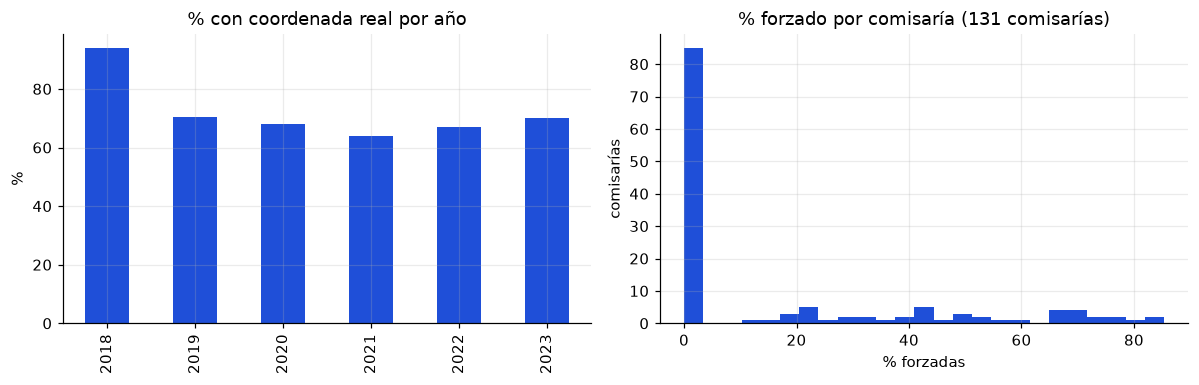

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
(d.groupby("anio").coord_real.mean().loc[2018:] * 100).plot.bar(ax=ax[0], color=AZUL)
ax[0].set(title="% con coordenada real por año", ylabel="%", xlabel="")
c = d.groupby("comisaria_hecho").falta.agg(["mean", "size"]).query("size > 500")["mean"] * 100
ax[1].hist(c, bins=25, color=AZUL); ax[1].set(title="% forzado por comisaría (131 comisarías)", xlabel="% forzadas", ylabel="comisarías")
plt.tight_layout(); guardar_fig("eda_sidpol_coordenadas.png")

### Qué encontramos (coordenadas)

- Las 581 057 forzadas caen en solo **96 puntos distintos** (78 comisarías). Son centroides, no hechos.
- Entre las coordenadas "reales" hay otro problema: **115 puntos se repiten 500 veces o más** (344 237 filas, 23,4 % de las reales). El mayor, en el Cercado de Lima (-12,0464; -77,0428), acumula 61 989 denuncias; le siguen San Juan de Lurigancho (22 368), Callao (19 037), Santa Anita (10 858) y Villa María del Triunfo (9 025). Son puntos por defecto del geocodificador cuando no entiende la dirección.
- 601 filas están marcadas `VERIFICAR/CORREGIR UBIGEO` (distrito dudoso).
- 100 % de las coordenadas están dentro del cuadro de Lima/Callao; no hay latitud/longitud invertidas. 78 filas son de Cañete, Huarochirí y Canta.
- Respecto a la mediana de su propio distrito, la distancia es de 1,7 km (mediana), 8,1 km (percentil 99) y 23,9 km (percentil 99,9). Solo 3 104 filas (0,28 %) pasan de 15 km y 221 de 25 km.

**Decisión:** (1) excluir forzadas; (2) **excluir las coordenadas apiladas** (lista guardada en `clean/puntos_apilados.parquet`, calculada solo con train); (3) mantener la bandera `verificar_ubigeo` sin borrar; (4) los casos a más de 15 km del distrito no se eliminan: casi siempre quedarán fuera por no caer en el entorno de ninguna estación o paradero.

## 4. Outliers — ¿qué vamos a hacer?

Siguiendo week10, los outliers **se marcan y se deciden, no se borran a ciegas**. Miramos: (a) fechas imposibles o
sospechosas (años 1923–2016, registro anterior al hecho, retrasos de décadas, hora `00:00` exacta como valor por defecto),
(b) celdas de ~250 m con conteos extremos (IQR), (c) saltos mensuales de más de 20 % que suelen ser cambios de registro.

In [9]:
print("Hechos por año (extremos):")
vc = d.anio.value_counts().sort_index(); print(vc[vc.index < 2018].sum(), "filas con año < 2018 · años distintos:", vc[vc.index < 2018].shape[0])
print(vc.loc[2017:].to_string())
retraso = (d.fecha_hora_registro_hecho - d.fecha_hora_hecho).dt.days
print(f"\nRegistro ANTERIOR al hecho: {(retraso<0).sum():,} ({(retraso<0).mean():.2%}) · retraso > 365 días: {(retraso>365).sum():,}")
print(f"Hora 00:00 exacta: {d.hora_00_exacta.sum():,} filas ({d.hora_00_exacta.mean():.1%} del total). Para comparar, TODA la hora 01:00-01:59 tiene {(d.fecha_hora_hecho.dt.hour==1).sum():,} filas ({(d.fecha_hora_hecho.dt.hour==1).mean():.1%})")
print(d.groupby("anio").hora_00_exacta.mean().loc[2018:].mul(100).round(1).to_string())

Hechos por año (extremos):
8432 filas con año < 2018 · años distintos: 40
anio
2017      4844
2018    286392
2019    288614
2020    278154
2021    348384
2022    393895
2023    446179

Registro ANTERIOR al hecho: 17,167 (0.84%) · retraso > 365 días: 15,043
Hora 00:00 exacta: 49,878 filas (2.4% del total). Para comparar, TODA la hora 01:00-01:59 tiene 40,675 filas (2.0%)
anio
2018    2.6
2019    2.6
2020    2.5
2021    2.2
2022    2.3
2023    2.2


**Lectura (fechas):** 8 432 filas son anteriores a 2018, 0,84 % tiene registro anterior al hecho y 2,4 % tiene la hora exactamente 00:00 (valor por defecto).

**Siguiente paso:** concentración espacial en celdas de ~250 m (IQR) y saltos mensuales.

11,784 celdas de ~250 m con eventos · Q1=3 Q3=47 · valla IQR=113
Celdas sobre la valla: 1,139 (9.7%) concentran 51.9% de los eventos · máx 1,851



Meses con salto > 20 % vs. mes anterior: [('2019-07', '-30%'), ('2019-09', '-44%'), ('2019-10', '-95%'), ('2019-11', '+1658%'), ('2019-12', '+135%'), ('2020-03', '-44%'), ('2020-04', '-75%'), ('2020-05', '+85%'), ('2020-06', '+45%'), ('2020-07', '+28%'), ('2021-02', '-24%'), ('2021-03', '+34%'), ('2022-12', '+49%')]


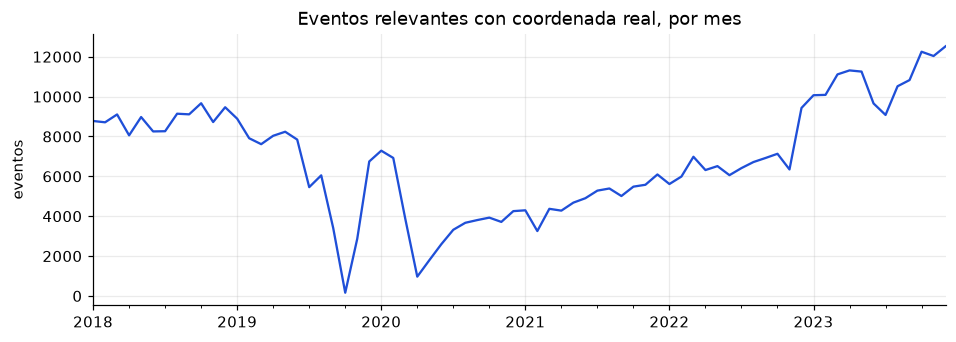

In [10]:
r = d[d.sirve_eje2 & d.coord_real & ~d.coord_apilada & d.anio.between(2018, 2023)]
celda = (r.lat_hecho / 0.00225).round().astype(int).astype(str) + "_" + (r.long_hecho / 0.00225).round().astype(int).astype(str)
cnt = celda.value_counts()
q1, q3 = cnt.quantile([.25, .75]); cerca = q3 + 1.5 * (q3 - q1)
print(f"{len(cnt):,} celdas de ~250 m con eventos · Q1={q1:.0f} Q3={q3:.0f} · valla IQR={cerca:.0f}")
print(f"Celdas sobre la valla: {(cnt>cerca).sum():,} ({(cnt>cerca).mean():.1%}) concentran {cnt[cnt>cerca].sum()/cnt.sum():.1%} de los eventos · máx {cnt.max():,}")
mens = r.set_index("fecha_hora_hecho").resample("MS").size()
salto = mens.pct_change().abs()
print("\nMeses con salto > 20 % vs. mes anterior:", [(str(i.date())[:7], f"{v:+.0%}") for i, v in mens.pct_change()[salto > .2].items()])
fig, ax = plt.subplots(figsize=(10, 3.2)); mens.plot(ax=ax, color=AZUL); ax.set(title="Eventos relevantes con coordenada real, por mes", xlabel="", ylabel="eventos")
guardar_fig("eda_sidpol_serie_mensual.png")

**Lectura (concentración):** 11 784 celdas con eventos; el 9,7 % de ellas (1 139) concentra 51,9 % de los eventos, y los saltos mensuales grandes coinciden con 2019 y con la pandemia de 2020.

**Siguiente paso:** medir la cobertura utilizable por mes, que es lo que explica los saltos de 2019.

Meses con < 50 % de coordenada utilizable (eventos relevantes):
                  total  pct_real  pct_utilizable
fecha_hora_hecho                                 
2019-09            9298        48              37
2019-10            8820         3               2
2019-11            9401        42              30

Alrededor de 2019 y de fines de 2023 (total de eventos relevantes vs % utilizable):
                  total  pct_real  pct_utilizable
fecha_hora_hecho                                 
2019-06           10431      95.0            75.0
2019-07            9727      73.0            56.0
2019-08           10171      77.0            59.0
2019-09            9298      48.0            37.0
2019-10            8820       3.0             2.0
2019-11            9401      42.0            30.0
2019-12           10359      86.0            65.0
2023-07           13485      76.0            67.0
2023-08           13710      88.0            77.0
2023-09           14551      84.0            74.0
2

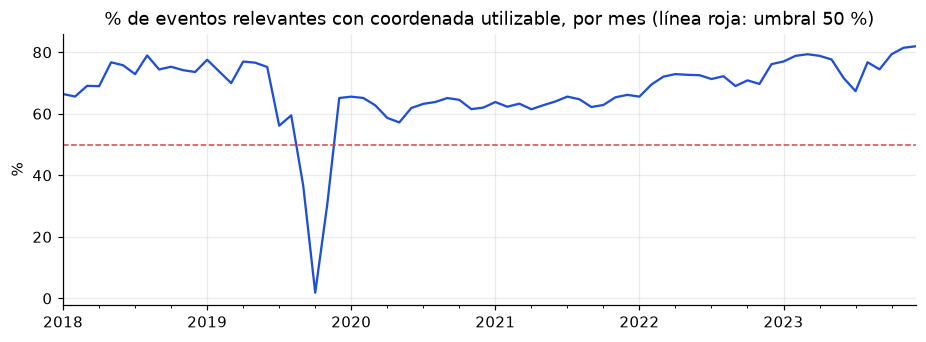


Guardado cobertura comisaría×año (eventos relevantes, meses válidos): 803 celdas · cobertura mediana 0.93


In [11]:
# Cobertura UTILIZABLE por mes, medida sobre los eventos RELEVANTES (si se midiera sobre todas las denuncias, las intervenciones policiales,
# que casi nunca tienen coordenada, la deprimirían). Utilizable = coordenada real y no apilada en un punto por defecto.
rel = d[(d.anio >= 2018) & d.sirve_eje2].copy()
rel["utilizable"] = rel.coord_real & ~rel.coord_apilada
cob = rel.groupby(rel.fecha_hora_hecho.dt.to_period("M")).agg(total=("id_dgc", "size"), pct_real=("coord_real", "mean"), pct_utilizable=("utilizable", "mean"))
bajos = cob[cob.pct_utilizable < 0.5]
print("Meses con < 50 % de coordenada utilizable (eventos relevantes):")
print(bajos.assign(pct_real=(bajos.pct_real * 100).round(0).astype(int), pct_utilizable=(bajos.pct_utilizable * 100).round(0).astype(int)).to_string())
print("\nAlrededor de 2019 y de fines de 2023 (total de eventos relevantes vs % utilizable):")
print(pd.concat([cob.loc["2019-06":"2019-12"], cob.loc["2023-07":"2023-12"]]).assign(pct_real=lambda x: (x.pct_real * 100).round(0), pct_utilizable=lambda x: (x.pct_utilizable * 100).round(0)).to_string())
print("\nPromedio de % utilizable por año:"); print((rel.groupby("anio").utilizable.mean() * 100).round(1).to_string())
fig, ax = plt.subplots(figsize=(10, 3.2)); (cob.pct_utilizable * 100).plot(ax=ax, color=AZUL); ax.axhline(50, color=ROJO, ls="--", lw=1)
ax.set(title="% de eventos relevantes con coordenada utilizable, por mes (línea roja: umbral 50 %)", ylabel="%", xlabel="")
guardar_fig("eda_sidpol_cobertura_mensual.png")
bajos.reset_index().assign(mes=lambda x: x.fecha_hora_hecho.astype(str)).drop(columns="fecha_hora_hecho").to_csv(CLEAN / "meses_baja_cobertura.csv", index=False)
ok_m = ~rel.fecha_hora_hecho.dt.to_period("M").isin(bajos.index)                       # solo meses con cobertura suficiente
cob_ca = rel[ok_m].groupby(["comisaria_hecho", "anio"]).agg(n=("id_dgc", "size"), cobertura=("utilizable", "mean")).reset_index()
cob_ca.to_csv(CLEAN / "cobertura_comisaria_anio.csv", index=False)
print(f"\nGuardado cobertura comisaría×año (eventos relevantes, meses válidos): {len(cob_ca):,} celdas · cobertura mediana {cob_ca.cobertura.median():.2f}")

### Qué encontramos (outliers y cobertura temporal)

**Fechas**
- 8 432 filas tienen año anterior a 2018 (40 años distintos, desde 1923; 4 844 son de 2017). **Se descartan.**
- En 17 167 filas (0,84 %) el registro es anterior al hecho y en 15 043 el retraso supera un año. No afectan la ubicación: se conservan y quedan como bandera.
- 49 878 filas (2,4 %) tienen la hora exactamente `00:00`. Esa sola marca pesa más que toda la hora 01:00–01:59 (40 675), así que es un **valor por defecto cuando no se sabe la hora**. Se excluyen de los análisis por hora; el `turno` se conserva.

**Concentración espacial (IQR por celdas de ~250 m)**
- 11 784 celdas con eventos; Q1 = 3, Q3 = 47, valla = 113. El **9,7 % de las celdas (1 139) concentra 51,9 % de los eventos**; la mayor tiene 1 851. Son puntos calientes reales (mercados, centros), no errores: se mantienen y se usará suavizado.

**Cobertura mensual (hallazgo clave)**
- Se mide la **coordenada utilizable** (real y no apilada) solo sobre los **eventos relevantes**. Medirla sobre todas las denuncias engaña: las intervenciones policiales, con 9,6 % de coordenada real, la deprimen.
- Promedio por año: 72,5 % (2018), 59,8 %, 63,4 %, 63,8 %, 71,3 % y 77,1 % (2023).
- El total de eventos relevantes **no cae** en los meses malos (9 298, 8 820 y 9 401), pero el % utilizable **se desploma**: septiembre de 2019 **37 %**, octubre de 2019 **2 %** y noviembre de 2019 **30 %**. En esos meses casi todo quedó forzado al centroide, probablemente porque la extracción es anterior a la corrección de coordenadas. De julio a diciembre de 2023 todos los meses están entre 67 % y 82 %.
- Si no se corrige, un modelo creería que las calles se volvieron seguras en esos tres meses.

**Decisión:** (a) se marcan los 3 meses con menos de 50 % utilizable (`clean/meses_baja_cobertura.csv`) y se **excluyen del conteo de eventos** que sirve de objetivo del modelo; (b) la cobertura por comisaría y año se guarda (`cobertura_comisaria_anio.csv`, 803 celdas, mediana 0,93) para ponderar, calculada **solo con eventos relevantes y meses válidos** (si incluyera los meses caídos, la exposición se penalizaría dos veces); (c) la misma regla (≥ 50 % por mes) se aplica a cualquier periodo que se evalúe, y la **reserva** (septiembre de 2024 a junio de 2025) queda fuera por no cumplirla.

## 5. Imputación — ¿qué vamos a hacer?

Cerca de un tercio de las denuncias no tiene coordenada real pero sí `direccion_hecho`. ¿Se puede **recuperar** la ubicación
geocodificando la dirección? Antes de decidir, medimos en una **muestra pequeña** con Nominatim (OpenStreetMap, ≤ 1 consulta/s):

- sobre denuncias con coordenada real: la **tasa de éxito** y el **error en metros** contra la coordenada conocida;
- sobre denuncias forzadas: la **tasa de éxito**.

Si el error es grande, la imputación mete ruido espacial y no se usa. La muestra se guarda en `clean/geocode_muestra.parquet`.

In [12]:
import requests
GEO = CLEAN / "geocode_muestra.parquet"
def tiene_calle(s): return s.fillna("").str.contains(r"\d|AV|JR|CALLE|PASAJE|JIRON|PSJ", regex=True, case=False)
ok = d.sirve_eje2 & d.anio.between(2018, 2023) & tiene_calle(d.direccion_hecho) & (d.direccion_hecho.str.len() > 10)
muestra = pd.concat([
    d[ok & (d.observacion == "COORDENADA OK") & ~d.coord_apilada].sample(100, random_state=SEED).assign(grupo_m="real"),
    d[ok & d.falta].sample(100, random_state=SEED).assign(grupo_m="forzada"),
])
def geocodificar(dir_, dist):
    q = f"{dir_}, {dist}, Lima, Perú"
    try:
        r = requests.get("https://nominatim.openstreetmap.org/search", params=dict(q=q, format="json", limit=1, countrycodes="pe"),
                         headers={"User-Agent": "UrbanSafeAI-UTEC-DPD/1.0 (investigacion academica)"}, timeout=20).json()
    except Exception:
        return np.nan, np.nan
    return (float(r[0]["lat"]), float(r[0]["lon"])) if r else (np.nan, np.nan)
if GEO.exists():
    g = pd.read_parquet(GEO)
else:
    out = []
    for _, x in muestra.iterrows():
        la, lo = geocodificar(x.direccion_hecho, x.distrito_hecho); out.append((la, lo)); time.sleep(1.1)
    g = muestra[["id_dgc", "grupo_m", "lat_hecho", "long_hecho", "direccion_hecho", "distrito_hecho"]].copy()
    g["geo_lat"], g["geo_lon"] = zip(*out); g.to_parquet(GEO, index=False)
g["encontrada"] = g.geo_lat.notna()
g["err_m"] = 111_200 * np.sqrt((g.geo_lat - g.lat_hecho) ** 2 + ((g.geo_lon - g.long_hecho) * np.cos(np.radians(12))) ** 2)
print(g.groupby("grupo_m").encontrada.agg(["mean", "size"]).round(3).to_string())
e = g[(g.grupo_m == "real") & g.encontrada].err_m
print("\nError vs. coordenada real (m):"); print(e.describe(percentiles=[.5, .75, .9]).round(0).to_string())
print(f"dentro de 100 m: {(e<100).mean():.0%} · dentro de 250 m: {(e<250).mean():.0%} · dentro de 500 m: {(e<500).mean():.0%}")

         mean  size
grupo_m            
forzada  0.16   100
real     0.09   100

Error vs. coordenada real (m):
count        9.0
mean      3183.0
std       5778.0
min          5.0
50%        316.0
75%       1068.0
90%      12909.0
max      14055.0
dentro de 100 m: 33% · dentro de 250 m: 44% · dentro de 500 m: 67%


### Qué encontramos (imputación por geocodificación)

- Con Nominatim (OpenStreetMap), solo **9 de 100** direcciones del grupo con coordenada real y **16 de 100** del grupo forzado se encontraron. Las direcciones peruanas (`MZ`, `LT`, "cuadra 5", nombres de asentamientos) casi nunca coinciden.
- En las 9 encontradas contra coordenada real, el error fue de **316 m (mediana)**: 33 % quedó a menos de 100 m y 44 % a menos de 250 m, pero el percentil 90 llegó a 12,9 km. Con solo 9 casos la estimación es poco precisa.

**Decisión:** **no imputar ubicaciones por geocodificación.** Recuperaría una fracción pequeña de las forzadas con errores a veces de kilómetros, lo que ensuciaría el riesgo por calle. Queda como trabajo futuro: un geocodificador local que entienda manzana/lote y nombres de vía peruanos.

## 6. Relevancia para el Eje 2 — ¿qué vamos a hacer?

No todas las denuncias dicen algo sobre caminar por una calle. Clasificamos cada hecho en un **grupo** (reglas en
`code/eje2/eje2_common.py`: `clasificar_grupo`) y decidimos cuáles **sirven** y cuáles **no**. Luego armamos el **embudo**
de filtros (grupo útil → coordenada real → no apilada → 2018–2023 → Lima/Callao) y guardamos el resultado.

In [13]:
t = d.groupby("grupo").agg(n=("id_dgc", "size"), pct_coord_real=("coord_real", "mean")).round(3)
t["sirve"] = [C.GRUPOS_EJE2[g] for g in t.index]
t["n_util"] = d[d.sirve_eje2 & d.coord_real & ~d.coord_apilada & d.anio.between(2018, 2023)].groupby("grupo").size().reindex(t.index).fillna(0).astype(int)
print(t.sort_values("n", ascending=False).to_string())
for g in ["acoso", "agresion_sexual", "violencia_fisica"]:
    print(g, d[d.grupo == g].modalidad_hecho.value_counts().head(4).to_dict())

pasos = [("total train+valid", len(d))]
m1 = d.sirve_eje2;                 pasos.append(("grupo útil para el peatón", int(m1.sum())))
m2 = m1 & d.coord_real;            pasos.append(("+ coordenada real (no forzada)", int(m2.sum())))
m3 = m2 & ~d.coord_apilada;        pasos.append(("+ no apilada en un punto por defecto", int(m3.sum())))
m4 = m3 & d.anio.between(C.ANIO_MIN, 2023); pasos.append(("+ años 2018–2023", int(m4.sum())))
m5 = m4 & d.provincia_hecho.isin(C.PROVINCIAS_OK); pasos.append(("+ Lima o Callao", int(m5.sum())))
embudo = pd.DataFrame(pasos, columns=["paso", "filas"]); embudo["% del total"] = (embudo.filas / len(d) * 100).round(1)
print("\n", embudo.to_string(index=False))

                            n  pct_coord_real  sirve  n_util
grupo                                                       
violencia_familiar     474431           0.935  False       0
intervencion_policial  408236           0.096  False       0
hurto                  369736            0.88   True  262646
robo_persona           236394           0.842   True  163474
otros                  222815           0.853  False       0
fraude_extorsion       146780           0.726  False       0
vehiculo                68559           0.873  False       0
violencia_fisica        55214           0.888   True   36650
agresion_sexual         45129            0.83   True   24479
acoso                   13848           0.791   True    8155
domicilio                8908            0.85  False       0
acoso {'ACOSO': 10100, 'ACOSO SEXUAL': 3120, 'ACOSO AGRAVADO': 383, 'ACOSO SEXUAL AGRAVADO': 245}
agresion_sexual {'ACTOS CONTRA EL PUDOR DE MENORES': 12928, 'VIOLACION SEXUAL': 11741, 'ACTOS CONTRA EL PUDOR

violencia_fisica {'LESIONES': 37528, 'LESIONES LEVES': 6412, 'LESIONES GRAVES': 3520, 'TENTATIVA DE HOMICIDIO': 3243}

                                 paso   filas  % del total
                   total train+valid 2050050        100.0
           grupo útil para el peatón  720321         35.1
      + coordenada real (no forzada)  622106         30.3
+ no apilada en un punto por defecto  497874         24.3
                    + años 2018–2023  495404         24.2
                     + Lima o Callao  495374         24.2


### Qué encontramos (relevancia para el Eje 2)

**Qué sirve:**
| Grupo | Filas útiles | Por qué |
|---|---|---|
| Hurto | 262 646 | riesgo del peatón (incluye hurto de celular) |
| Robo a la persona | 163 474 | el riesgo principal |
| Violencia física (lesiones, homicidio, tentativas) | 36 650 | agresión en la calle |
| Agresión sexual | 24 479 | violación, tocamientos, actos contra el pudor |
| Acoso (acoso y acoso sexual) | 8 155 | señal propia, pocos casos y muy subregistrada |

**Qué no sirve:** violencia familiar (474 431; ocurre en el hogar), intervenciones policiales (408 236; solo 9,6 % con coordenada real), fraude/extorsión/informáticos (146 780; sin ubicación callejera), robo/hurto de vehículos (68 559), hurto en casa habitada (8 908) y "otros" (222 815: conducción en estado de ebriedad, desobediencia, faltas como agresión sin daño).

**Embudo (train + valid):** 2 050 050 → 720 321 (grupo útil, 35,1 %) → 622 106 (coordenada real) → 497 874 (no apilada) → 495 404 (2018–2023) → **495 374 (Lima/Callao, 24,2 %)**. Quedan 364 647 en train y 130 727 en valid.

**Decisión:** usar estos cinco grupos. Acoso y agresión sexual se mantienen como señales separadas aunque sean pocas. Los grupos y sus reglas están en `eje2_common.py`.

## 7. Patrones temporales y espaciales — ¿qué vamos a hacer?

Sobre el conjunto filtrado: perfil por **turno** y por hora, día de la semana, mezcla de grupos por año y un mapa de
densidad. Además comprobamos el **sesgo de cobertura**: dónde falta coordenada real (porque ahí el riesgo se subestima).

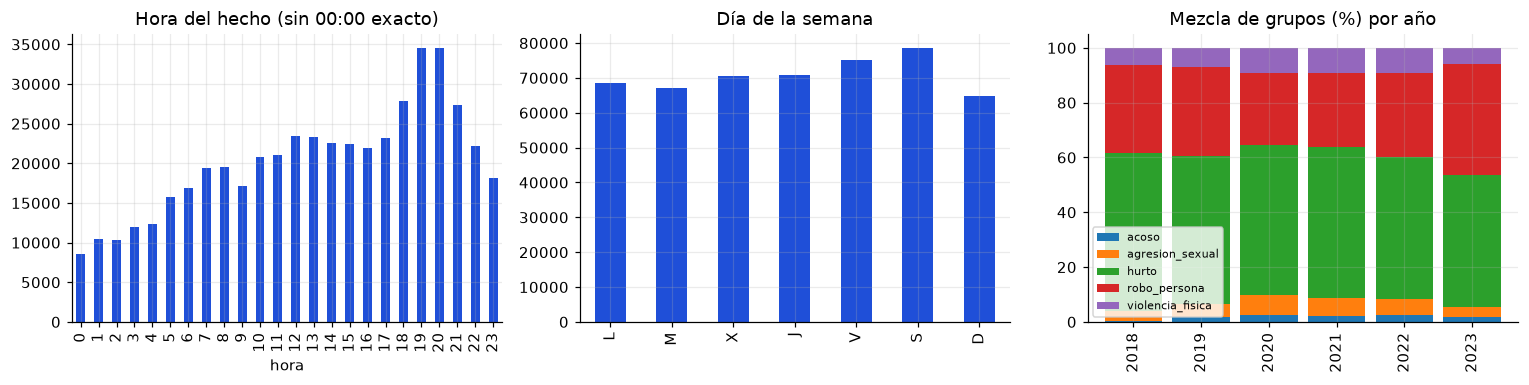

turno_hecho       madrugada  mañana  noche  tarde
grupo                                            
acoso                  10.9    26.5   30.3   32.2
agresion_sexual        21.7    20.5   29.5   28.3
hurto                  13.5    25.3   30.0   31.3
robo_persona           19.0    20.7   38.5   21.8
violencia_fisica       17.8    20.4   35.4   26.4


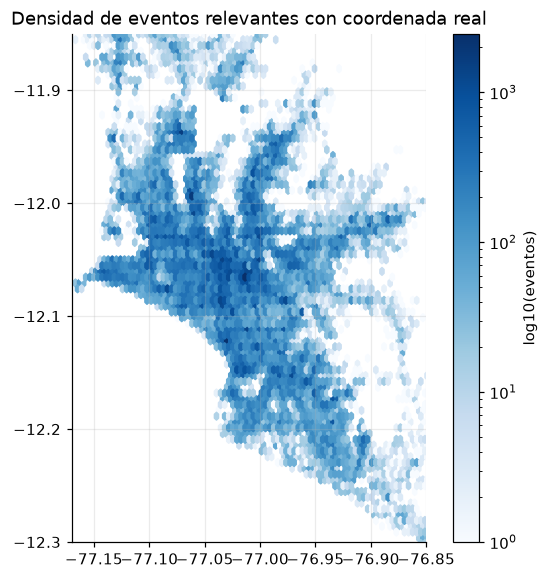

                        % forzada       n
distrito_hecho                           
SAN JUAN DE LURIGANCHO          0  143107
LIMA                            0  148421
SANTA ANITA                    11   80569
LURIGANCHO                     11   21420
LOS OLIVOS                     52   50003
EL AGUSTINO                    55   70769
INDEPENDENCIA                  59   92396
VILLA EL SALVADOR              59  112389


In [14]:
u = d[m5].copy()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
u[~u.hora_00_exacta].fecha_hora_hecho.dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], color=AZUL); ax[0].set(title="Hora del hecho (sin 00:00 exacto)", xlabel="hora")
u.fecha_hora_hecho.dt.dayofweek.value_counts().sort_index().rename(index=dict(enumerate("LMXJVSD"))).plot.bar(ax=ax[1], color=AZUL); ax[1].set(title="Día de la semana", xlabel="")
pd.crosstab(u.anio, u.grupo, normalize="index").mul(100).plot.bar(stacked=True, ax=ax[2], legend=True, width=.85); ax[2].set(title="Mezcla de grupos (%) por año", xlabel=""); ax[2].legend(fontsize=7, loc="lower left")
plt.tight_layout(); guardar_fig("eda_sidpol_patrones_temporales.png")
print(pd.crosstab(u.grupo, u.turno_hecho, normalize="index").mul(100).round(1).to_string())
fig, ax = plt.subplots(figsize=(6.4, 6)); s = u.sample(min(len(u), 400_000), random_state=SEED)
hb = ax.hexbin(s.long_hecho, s.lat_hecho, gridsize=140, bins="log", cmap="Blues", mincnt=1); ax.set(title="Densidad de eventos relevantes con coordenada real", xlim=(-77.17, -76.85), ylim=(-12.30, -11.85), aspect=1.02)
plt.colorbar(hb, label="log10(eventos)"); guardar_fig("eda_sidpol_mapa_densidad.png")
top = d[d.provincia_hecho.isin(C.PROVINCIAS_OK)].groupby("distrito_hecho").agg(n=("id_dgc", "size"), pct_forzada=("falta", "mean")); top = top[top.n > 20000].sort_values("pct_forzada")
print((top.pct_forzada * 100).round(0).astype(int).rename("% forzada").to_frame().assign(n=top.n).iloc[[0, 1, 2, 3, -4, -3, -2, -1]].to_string())

### Qué encontramos (patrones)

- **Por turno:** el robo a la persona es el más nocturno (38,5 % de noche y 19,0 % de madrugada). El acoso ocurre sobre todo de día (26,5 % mañana, 32,2 % tarde, solo 10,9 % de madrugada). La agresión sexual es la que más pesa en la madrugada (21,7 %).
- Hay un patrón semanal y de hora visible en las figuras `eda_sidpol_patrones_temporales.png`, y la mezcla de grupos cambia por año.
- **Sesgo de cobertura por distrito:** San Juan de Lurigancho y Lima tienen **0 %** de coordenadas forzadas; Santa Anita y Lurigancho 11 %; mientras Los Olivos (52 %), El Agustino (55 %), Villa El Salvador (59 %) e Independencia (59 %) tienen más de la mitad forzada. El mapa de densidad de eventos con coordenada real **subestima** esas zonas.

**Decisión:** el riesgo se reportará con la cobertura de cada zona junto al puntaje y se ponderará por cobertura; las zonas de baja cobertura tendrán menor confianza en las etiquetas de la app.

## 8. Conclusiones y guardado

In [15]:
cols = ["id_dgc", "fecha_hora_hecho", "anio", "turno_hecho", "hora_00_exacta", "lat_hecho", "long_hecho", "distrito_hecho",
        "provincia_hecho", "comisaria_hecho", "grupo", "tipo_hecho", "modalidad_hecho", "tipo_via_hecho", "observacion",
        "verificar_ubigeo", "split"]
u[cols].to_parquet(CLEAN / "denuncias_eje2_clean.parquet", index=False)
embudo.to_csv(CLEAN / "embudo_filtros.csv", index=False)
d.groupby(["anio", "grupo"]).agg(n=("id_dgc", "size"), pct_real=("coord_real", "mean")).round(3).to_csv(CLEAN / "resumen_calidad_anio_grupo.csv")
print(f"Guardado: {len(u):,} filas -> {CLEAN/'denuncias_eje2_clean.parquet'}")
print(u.groupby("split").size().to_dict())

Guardado: 495,374 filas -> /home/evssz/UTEC/6to/DPD/DPD_project/deliveries/week12/data_processed/eje2/clean/denuncias_eje2_clean.parquet
{'train': 364647, 'valid': 130727}


### Conclusiones

1. **El dataset sirve, pero solo ~24 % de las filas** (495 374 de 2 050 050) son útiles para riesgo por calle: hecho callejero, coordenada real, no apilada, 2018–2023, Lima o Callao.
2. **Los nulos están disfrazados:** lat/long nunca están vacías, pero 28,3 % son centroides de comisaría. `estado_coord` no es confiable; se usa `observacion`.
3. **La falta de coordenada es MAR (semi-aleatoria), no MCAR:** la explica la comisaría (AUC 0,93) y el periodo; MNAR no se puede descartar. Se corrige con ponderación por cobertura, no con imputación.
4. **No se imputa por geocodificación** (9–16 % de éxito y errores de hasta kilómetros).
5. **23,4 % de las coordenadas "reales" son puntos por defecto repetidos** y se excluyen.
6. **La cobertura utilizable se desploma en septiembre–noviembre de 2019 (2–37 %):** esos 3 meses no entran al objetivo del modelo. La misma regla se aplica a cualquier periodo evaluado.
7. **Hay mucha concentración espacial** (9,7 % de las celdas tiene 51,9 % de los eventos): se mantiene y se suaviza.
8. **Sesgos a declarar:** subregistro (sobre todo en acoso), sesgo social de quién denuncia, y cobertura desigual entre comisarías.

**Salidas** (en `data_processed/eje2/clean/`): `denuncias_eje2_clean.parquet`, `puntos_apilados.parquet`, `meses_baja_cobertura.csv`, `cobertura_comisaria_anio.csv`, `embudo_filtros.csv`, `resumen_calidad_anio_grupo.csv`, `geocode_muestra.parquet`.